A carry-loss probability combines defender reachability with a tackle rate and shared survival. The examples below use the **final fitted spline model**, loaded from its verified full-data export. All displayed tracking states are synthetic; measured OOF performance is in the [benchmark vignette](../../benchmark.qmd).

## Where the model comes from

Bekkers motivates moving-target TTI and logistic reachability [@bekkers2025]. Spearman motivates arrival uncertainty, control rates and competition for unclaimed probability mass [@spearman2017; @spearman2018beyond]. PRESS adds a learned tackle rate and carry-loss likelihood; it does not copy Bekkers's aggregate pressing score. **own derivation**

Fernández provides the one-second action decomposition [@fernandez2019; @fernandez2021]. Stalpaert's carry component supplies a tree-model benchmark and a resampling extension [@stalpaert2022]. Schepers et al. motivate examining speed and boundary proximity; their episode maxima, sideline-only distance and 3D dribble task differ from our initial-frame predictors [@schepers2025dribble].

## Point carrier and individual defender motion

The carrier follows $x_B(t)=x_B(0)+v_B(0)t$. At each integration time, defender $i$ targets this projected point; no engagement disk is used. Let $d_i(t)$ be its initial distance to that target and $u_i=\|v_i(0)\|$. With $a=a_{linear}$,

$$t_a=\max\{(v_{max}-u_i)/a,0\},\qquad d_a=u_i t_a+\tfrac12 a t_a^2.$$

For $u_i\leq v_{max}$,

$$t_{move}=\begin{cases}
(\sqrt{u_i^2+2ad_i}-u_i)/a,&d_i\leq d_a,\\
t_a+(d_i-d_a)/v_{max},&d_i>d_a.
\end{cases}$$

When $u_i>v_{max}$, retain the observed initial speed and use $t_{move}=d_i/u_i$, without further acceleration. The turning delay is $t_{turn}=u_i\theta_i/a_{turn}$, with radians; this comes from $R=u_i^2/a_{turn}$ and arc time $R\theta_i/u_i$. The implementation adds the delay without updating position along an arc: it is a simplified realignment routine. Arrival time is $\tau_i=t_{move}+t_{turn}$, with the existing near-target convention $\tau_i=0$ for $d_i\leq0.1$ m. This does **not** set the reachability CDF to one. **design choice**

## Reachability, tackle rate and loss likelihood

The Spearman-style logistic gate uses a standard-deviation parameter $s$ in seconds:

$$F_i(t)=\left[1+\exp\left\{-\frac{\pi(t-\tau_i(t))}{\sqrt3\,s}\right\}\right]^{-1}.$$

The baseline log-linear tackle model is

$$\lambda_i(t)=\lambda_0\exp\{\beta_v\|v_B\|+\beta_B B(t)\}.$$

The final version replaces the linear effects with penalized additive effects and adds individual approach angle:

$$\log\lambda_i(t)=\alpha+g_v(\|v_B\|)+g_B(B(t))+g_\phi(\phi_i(t)).$$

Speed and boundary effects retain linear terms plus restricted cubic nonlinear terms; angle has a standardized linear term plus two nonlinear terms. There are no interactions. The angle is between carrier velocity and the predicted final defender approach to $x_B(t)$; its contribution is masked for carrier speed below 1 m/s or undefined direction. It is not measured body orientation. $B(t)=\min\{L/2-x,L/2+x,W/2-y,W/2+y\}$ is the **signed minimum distance to all four lines**, recalculated along the path. **own derivation**

The effective cause hazard is $h_i(t)=F_i(t)\lambda_i(t)$, not $F_i$ alone. Thus

$$S(t)=\exp\!\left[-\int_0^t\sum_i h_i(u)\,du\right],\qquad
P_i(t)=\int_0^t S(u)h_i(u)\,du,\qquad P(loss\leq t\mid carry)=1-S(t)=\sum_i P_i(t).$$

$\lambda$ is a rate in s$^{-1}$ and may exceed one. Each defender contributes reachability, so number and proximity already affect total risk; coordinated defensive behaviour is not fully represented. With frozen step hazards $H=\sum_i h_i$ and step width $\Delta$, exponential Euler allocates $S(1-e^{-H\Delta})h_i/H$ to cause $i$ and updates $S\leftarrow Se^{-H\Delta}$. This preserves mass; rates vary over time and timestep accuracy remains a separate question. Default $\Delta=0.04$ s, with partial final steps. **own derivation**

The log-linear baseline is described as proportional-hazards-inspired. The spline extension still has a multiplicative hazard structure; it relaxes covariate shape, not every proportionality assumption. The full hazards include time-varying gates and boundary/angle values, so this is not a textbook constant-hazard-ratio Cox model. **design choice**

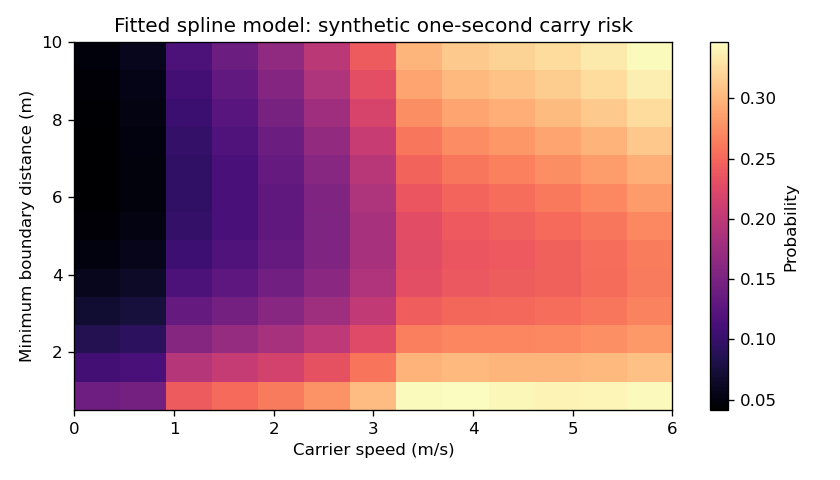

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.model import BallDriveModel

fitted_model = BallDriveModel.pretrained()

def risk(speed, boundary_distance):
    # Synthetic geometry: two defenders, fixed positions and velocities.
    carrier = np.array([-52.5 + boundary_distance, 0.0])
    defenders = carrier[None, :] + np.array([[3.5, 0.0], [0.0, 5.0]])
    velocities = np.zeros_like(defenders)
    carrier_v = np.array([[speed, 0.0]])
    result = fitted_model.predict(defenders, velocities, carrier, carrier_v[0], horizon=1.0)
    return float(result['loss_probability'])
speeds = np.linspace(0, 6, 13)
distances = np.linspace(0.5, 10, 13)
Z = np.array([[risk(v, d) for v in speeds] for d in distances])
fig, ax = plt.subplots(figsize=(7, 4))
image=ax.imshow(Z, origin="lower", aspect="auto", extent=[speeds.min(), speeds.max(), distances.min(), distances.max()], cmap="magma")
ax.set(xlabel="Carrier speed (m/s)", ylabel="Minimum boundary distance (m)", title="Fitted spline model: synthetic one-second carry risk")
fig.colorbar(image, ax=ax, label="Probability")
fig.tight_layout()
out=Path("figures/vignette_01_drive_risk.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
plt.show()

### Cohort, likelihood and interpretation

The one-second target is Bernoulli: a terminal carry loss, even before one second, contributes $1-S(1)$; a complete successful carry contributes $S(1)$. Successful short tails, goalkeeper carriers and shot-ending individual possessions are excluded from training. Failed passes are not carry losses. Additional snapshots remain usable for inference and do not become action-selection training rows. Splitting drives into canonical sections follows the EPV motivation [@fernandez2021], with the accepted project tail/label convention documented separately. **design choice**

The final model uses natural class proportions, not resampling, and estimates average skills. Body posture, foot-level control and player-specific skill are unavailable. Overlap of 2D covariates between successful and failed carries does not prove that all useful 2D signal has been exhausted. [@schepers2025dribble] motivates posture as an extension, not a claim that 3D data are necessary for every remaining improvement. Short-horizon probabilities are supported mathematically but have not received separate calibration studies.

### Why vmax = 7 and a_linear = a_turn = 7?

The tracking audit distinguishes event-frame samples from per-engagement peaks. Pooled matched on-ball engagements give:

| Defensive engager quantity | Conditioning | N selected | P95 | P99 |
|---|---|---:|---:|---:|
| Speed in event frames (m/s) | speed > 1 | 95,236 | 6.954 | 8.002 |
| Peak speed per engagement (m/s) | both carrier/engager peaks > 1 | 6,197 | 7.248 | 8.236 |
| Peak acceleration magnitude per engagement (m/s²) | peak magnitude > 3 | 3,877 | 6.000 | 6.966 |

The acceleration row comes from 6,677 matched engagements before the >3 filter. Event-frame weighting may repeat frames when engagements overlap. These are conditional empirical quantiles, not unconditional population percentiles or measured physiological ceilings. Seven m/s is an effective high engagement speed, not a hard cap on observed initial speed. Seven m/s² is close to the conditional P99 peak-acceleration magnitude and matches the acceleration used by Spearman in §3.1.1 [@spearman2018beyond]; his reference sustainable speed is 5 m/s, not our carry value. **design choice**

Tracking acceleration is a smoothed vector magnitude; these statistics do not independently identify maximal tangential and centripetal acceleration. Setting the two parameters equal is the benchmark convention. They remain separately configurable. The runtime reads positions and velocities, not observed acceleration. The seven-frame centred velocity estimate also makes this an offline, rather than strictly causal online, evaluation. The [quantile table](../../data/benchmarks/ball_drive/engagement_quantiles.csv) and [provenance](../../data/benchmarks/ball_drive/provenance.json) identify population, filters and source hashes.

The final ten-match refit has $s=0.352790$ s and $\lambda_0=0.334747$ s$^{-1}$. These coefficients belong to the fitted basis convention and should not be interpreted as population-average probabilities.

## Use the fitted model on a selected frame

Initialize one synthetic match, select a possession and an interior frame, load the final model and use the package pitch plot. This is an executable usage example, not a benchmark observation. To load local processed tracking, use `PRESS.from_skillcorner(...)` and pass the fitted model per calculation, as described in the [match guide](../../usage.qmd) and [API](../../api.qmd).


frame: 5
{'Individual tackle probabilities': array([2.65048354e-19, 4.18078302e-14, 2.03388471e-13, 3.28378860e-14,
       3.99135709e-16, 4.35897665e-07, 1.91721466e-05, 2.62270562e-07,
       1.10445448e-10, 2.35135714e-03, 1.22563883e-07]), 'Ball drive loss probability': np.float64(0.002371350125181002), 'Survival probability': np.float64(0.997628649874819), 'Survival curve': array([1.        , 0.99999599, 0.99999111, 0.99998519, 0.99997799,
       0.99996924, 0.9999586 , 0.99994569, 0.99992999, 0.99991092,
       0.99988775, 0.99985961, 0.99982543, 0.99978391, 0.9997335 ,
       0.9996723 , 0.99959801, 0.99950786, 0.99939849, 0.99926586,
       0.99910509, 0.99891034, 0.99867456, 0.99838935, 0.99804469,
       0.99762865]), 'Times': array([0.  , 0.04, 0.08, 0.12, 0.16, 0.2 , 0.24, 0.28, 0.32, 0.36, 0.4 ,
       0.44, 0.48, 0.52, 0.56, 0.6 , 0.64, 0.68, 0.72, 0.76, 0.8 , 0.84,
       0.88, 0.92, 0.96, 1.  ]), 'params': {'t_press': 1.0, 'physics_kwargs': {'v_max': 7.0, 'a_linear': 7.

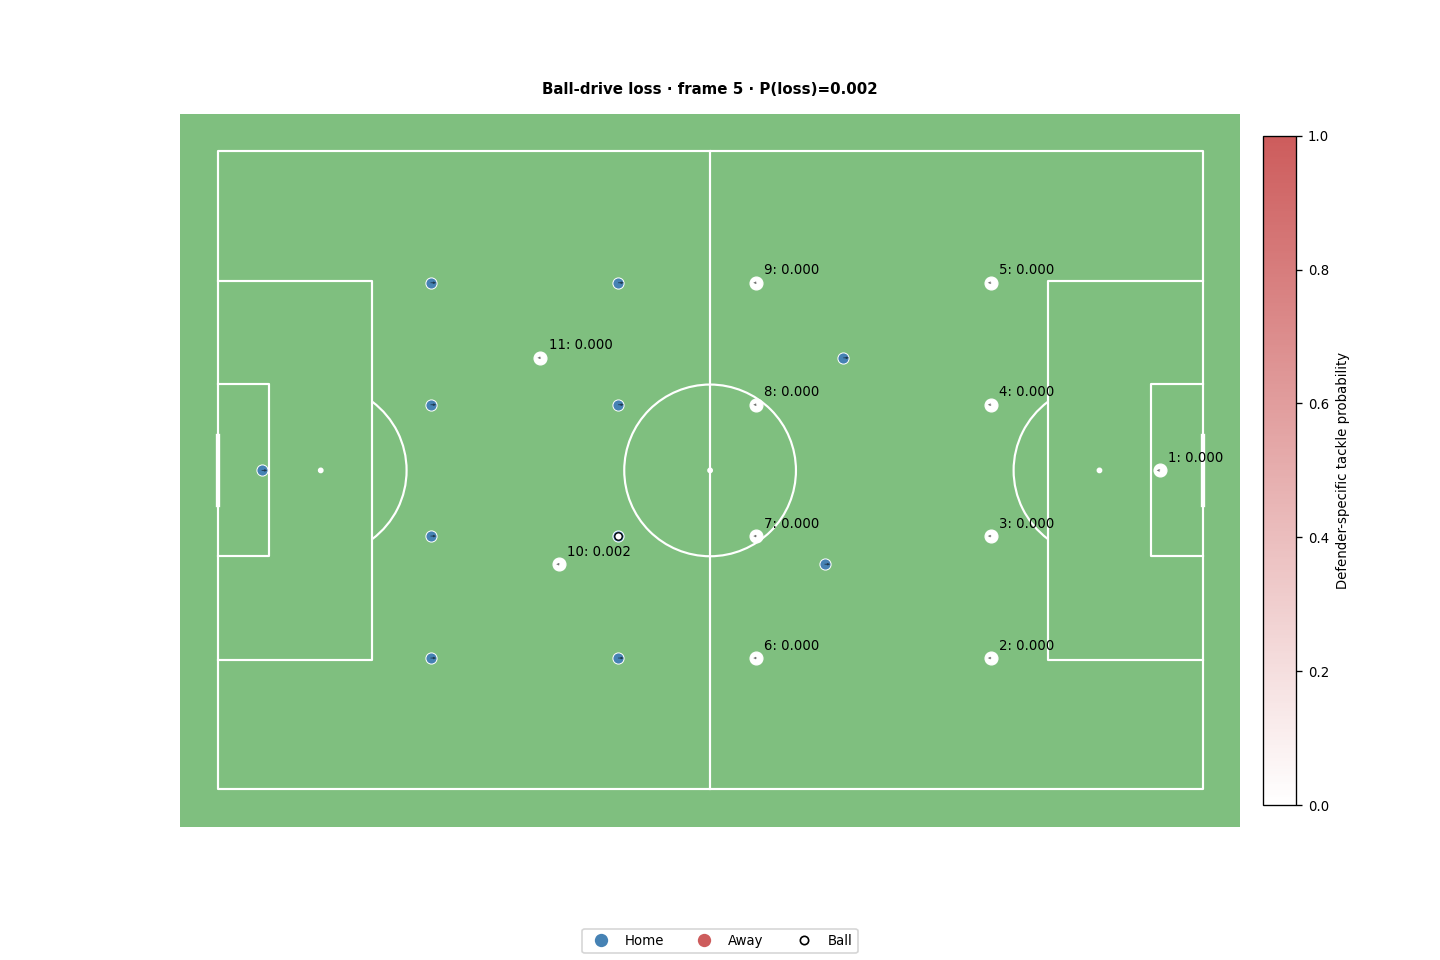

In [6]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions,
              ball_drive_model=BallDriveModel.pretrained())
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ball_drive_loss(frame_id)
print("frame:", frame_id)
print(model.get_ball_drive_result(frame_id))

from PRESS.visualization import plot_pi
plot_pi(model, frame_id)
fig = plt.gcf()
out = Path("figures/vignette_01_drive_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))


## References and next steps

- Bekkers: moving-target pressing/reachability [@bekkers2025].
- Spearman: arrival uncertainty, shared control mass and control rates [@spearman2017; @spearman2018beyond].
- Fernández, Bornn and Cervone: action decomposition and one-second carry model [@fernandez2019; @fernandez2021].
- Stalpaert: CatBoost carry benchmark and training resampling [@stalpaert2022].
- Schepers, Robberechts, Van Haaren and Davis: 2D/3D dribble covariates and encounter geometry [@schepers2025dribble].

The model equations above are the PRESS formulation; citations identify the building blocks and empirical motivation. See the [benchmark](../../benchmark.qmd) for proportional-hazard-inspired versus spline results, published comparisons and the CatBoost + resampling extension. The legacy `integrate_loss_prob` and `PRESS` without an explicit fitted model retain the historical log-linear interface. The pass component is reviewed separately.
